In [1]:
import pandas as pd

In [2]:
df_matches = pd.read_csv("data/cleaned_matches.csv")

In [3]:
# Print column names
print("Columns in dataset:")
print(df_matches.columns.tolist())

Columns in dataset:
['Unnamed: 0', 'match_id', 'date', 'match_type', 'event_name', 'innings', 'batting_team', 'bowling_team', 'over', 'ball', 'ball_no', 'batter', 'bat_pos', 'runs_batter', 'balls_faced', 'bowler', 'valid_ball', 'runs_extras', 'runs_total', 'runs_bowler', 'runs_not_boundary', 'extra_type', 'non_striker', 'non_striker_pos', 'wicket_kind', 'player_out', 'fielders', 'runs_target', 'review_batter', 'team_reviewed', 'review_decision', 'umpire', 'umpires_call', 'player_of_match', 'match_won_by', 'win_outcome', 'toss_winner', 'toss_decision', 'venue', 'city', 'day', 'month', 'year', 'season', 'gender', 'team_type', 'superover_winner', 'result_type', 'method', 'balls_per_over', 'overs', 'event_match_no', 'stage', 'match_number', 'team_runs', 'team_balls', 'team_wicket', 'new_batter', 'batter_runs', 'batter_balls', 'bowler_wicket', 'batting_partners', 'next_batter', 'striker_out', 'toss_match_winner']


In [4]:
# BASELINE CLASSIFICATION MODEL ( PREDICTING MATCH WINNER)

In [5]:
import pandas as pd

# Load dataset
df = pd.read_csv(r"C:\Users\sohag\Downloads\IDC 409\data\cleaned_matches.csv")

# Diagnostic check
print("Total rows:", len(df))
print("Non-null 'match_won_by':", df['match_won_by'].notna().sum() if 'match_won_by' in df.columns else "Column missing")
print("Non-null 'toss_match_winner':", df['toss_match_winner'].notna().sum() if 'toss_match_winner' in df.columns else "Column missing")
print("Unique match_ids:", df['match_id'].nunique())

Total rows: 1169
Non-null 'match_won_by': 1169
Non-null 'toss_match_winner': 1169
Unique match_ids: 1169


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# 1. Load Data
df_matches = pd.read_csv(r"C:\Users\sohag\Downloads\IDC 409\data\cleaned_matches.csv")
df_matches.columns = df_matches.columns.str.strip()

# 2. Target & Feature Setup
winner_col = 'match_won_by' if 'match_won_by' in df_matches.columns else 'toss_match_winner'

# Ensure season is numeric if passed through
if 'season' in df_matches.columns:
    df_matches['season'] = pd.to_numeric(df_matches['season'], errors='coerce')

# Filter out rows with missing critical information
df_clf = df_matches.dropna(subset=[winner_col, 'venue', 'toss_winner', 'toss_decision', 'season']).copy()

# Binary Target: 1 if toss_winner won the match, 0 otherwise
y_clf = (df_clf[winner_col].str.strip() == df_clf['toss_winner'].str.strip()).astype(int)

cat_cols = ['venue', 'toss_winner', 'toss_decision']
features = cat_cols + ['season']
X_clf = df_clf[features]

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# 4. Dense OneHot Preprocessor
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor_clf = ColumnTransformer(
    transformers=[('cat', ohe, cat_cols)],
    remainder='passthrough'
)

X_train_enc = preprocessor_clf.fit_transform(X_train)
X_test_enc = preprocessor_clf.transform(X_test)

# 5. Baseline Classifier
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train_enc, y_train)
base_preds = baseline.predict(X_test_enc)

# 6. Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train_enc, y_train)
rf_preds = rf_clf.predict(X_test_enc)

# 7. Deliverables & Evaluation Metrics
print("=== CLASSIFICATION RESULTS ===")
print("Baseline Accuracy:     ", round(accuracy_score(y_test, base_preds), 4))
print("Random Forest Accuracy:", round(accuracy_score(y_test, rf_preds), 4))
print("Random Forest F1-Score:", round(f1_score(y_test, rf_preds), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, rf_preds))

=== CLASSIFICATION RESULTS ===
Baseline Accuracy:      0.5126
Random Forest Accuracy: 0.4724
Random Forest F1-Score: 0.4928

Confusion Matrix:
 [[43 54]
 [51 51]]


In [7]:
# CONFUSION MATRIX HEATMAP

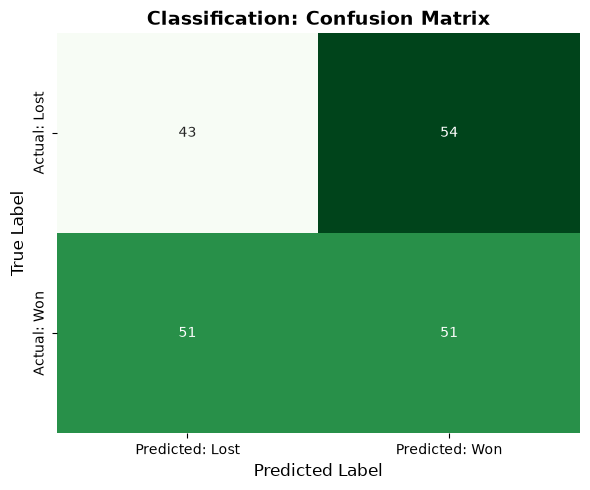

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix array
cm = confusion_matrix(y_test, rf_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Predicted: Lost', 'Predicted: Won'],
            yticklabels=['Actual: Lost', 'Actual: Won'])

plt.title('Classification: Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

In [9]:
# MODEL PERFORMANCE COMPARISON BAR CHART

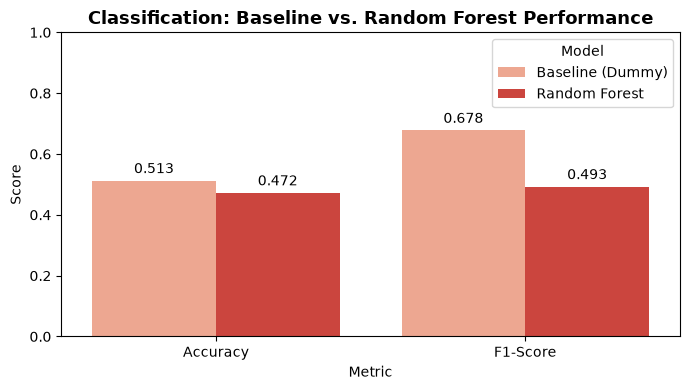

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

metrics_df = pd.DataFrame({
    'Model': ['Baseline (Dummy)', 'Baseline (Dummy)', 'Random Forest', 'Random Forest'],
    'Metric': ['Accuracy', 'F1-Score', 'Accuracy', 'F1-Score'],
    'Score': [
        accuracy_score(y_test, base_preds),
        f1_score(y_test, base_preds, zero_division=0),
        accuracy_score(y_test, rf_preds),
        f1_score(y_test, rf_preds)
    ]
})

plt.figure(figsize=(7, 4))
ax = sns.barplot(data=metrics_df, x='Metric', y='Score', hue='Model', palette='Reds')

plt.title('Classification: Baseline vs. Random Forest Performance', fontsize=13, fontweight='bold')
plt.ylim(0, 1.0)
plt.ylabel('Score')

# Display exact numbers on top of bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.3f}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3), 
                    textcoords='offset points')

plt.tight_layout()
plt.show()

In [11]:
# REGRESSION MODEL (PREDICTING FIRST-INNINGS TOTAL/RUNS)

In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Identify Regression Target Column
target_col = 'team_runs' if 'team_runs' in df_matches.columns else ('runs_target' if 'runs_target' in df_matches.columns else None)

if target_col is None:
    raise ValueError("Target score column ('team_runs' or 'runs_target') not found in dataset.")

# Ensure season is numeric
if 'season' in df_matches.columns:
    df_matches['season'] = pd.to_numeric(df_matches['season'], errors='coerce')

# Filter out rows missing features or target score
df_reg = df_matches.dropna(subset=[target_col, 'venue', 'toss_winner', 'toss_decision', 'season']).copy()

cat_cols = ['venue', 'toss_winner', 'toss_decision']
features = cat_cols + ['season']

X_reg = df_reg[features]
y_reg = df_reg[target_col]

# Train-Test Split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Dense OneHot Preprocessor
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor_reg = ColumnTransformer(
    transformers=[('cat', ohe, cat_cols)],
    remainder='passthrough'
)

X_train_r_enc = preprocessor_reg.fit_transform(X_train_r)
X_test_r_enc = preprocessor_reg.transform(X_test_r)

# Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train_r_enc, y_train_r)
reg_preds = rf_reg.predict(X_test_r_enc)

# Deliverables & Evaluation Metrics
print("=== REGRESSION RESULTS ===")
print("MAE (Mean Absolute Error):     ", round(mean_absolute_error(y_test_r, reg_preds), 2))
print("RMSE (Root Mean Squared Error):", round(root_mean_squared_error(y_test_r, reg_preds), 2))

=== REGRESSION RESULTS ===
MAE (Mean Absolute Error):      1.06
RMSE (Root Mean Squared Error): 1.52


In [13]:
# AUCTUAL VS PREDICTED TARGET SCORES PLOT

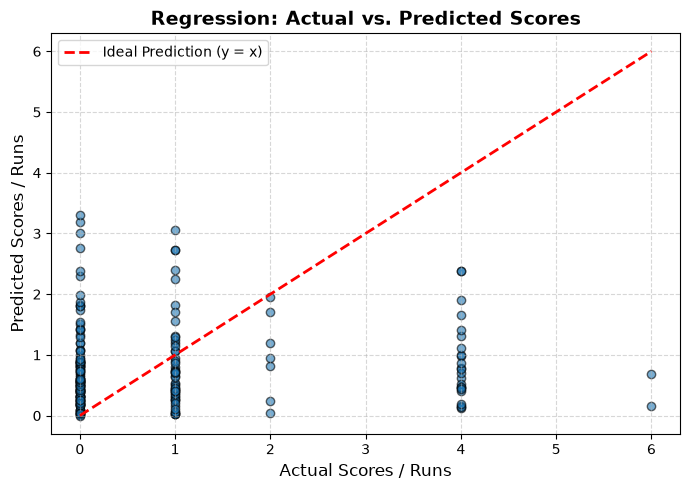

In [14]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test_r, reg_preds, alpha=0.6, color='#1f77b4', edgecolors='k')

# Draw ideal y = x reference line
min_val = min(y_test_r.min(), reg_preds.min())
max_val = max(y_test_r.max(), reg_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Ideal Prediction (y = x)')

plt.title('Regression: Actual vs. Predicted Scores', fontsize=14, fontweight='bold')
plt.xlabel('Actual Scores / Runs', fontsize=12)
plt.ylabel('Predicted Scores / Runs', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [15]:
# RESIDUALS/ ERROR DISTRIBUTION PLOT

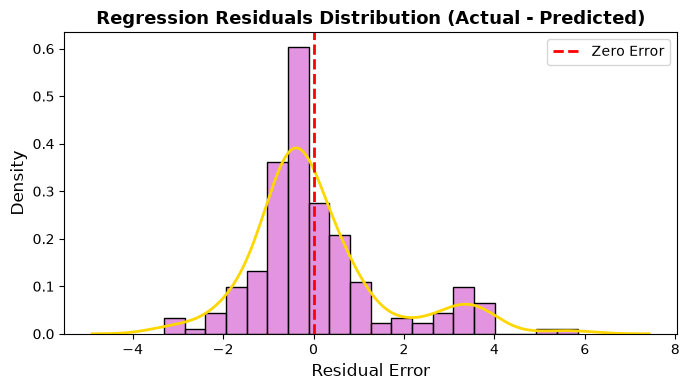

In [16]:
residuals = y_test_r - reg_preds

plt.figure(figsize=(7, 4))
# 1. Plot histogram bars
sns.histplot(residuals, color='orchid', bins=20, stat='density')

# 2. Plot KDE curve on top with custom color
sns.kdeplot(residuals, color='gold', linewidth=2)

plt.axvline(0, color='red', linestyle='--', linewidth=2, label='Zero Error')
plt.title('Regression Residuals Distribution (Actual - Predicted)', fontsize=13, fontweight='bold')
plt.xlabel('Residual Error', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
#UNSUPERVISED PITCH AND VENUE CLUSTERING (K-MEANS)

C:\Users\sohag\AppData\Local\Temp\ipykernel_15904\3997268977.py:6: DtypeWarning: Columns (28: review_batter, 29: team_reviewed, 30: review_decision, 31: umpire, 43: season, 46: superover_winner, 47: result_type, 48: method, 51: event_match_no) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ball = pd.read_csv(kaggle_path)


Total ball-by-ball rows loaded: 278,205
Successfully aggregated 1169 unique matches.
Average 1st Innings Score: 167.0 runs

=== REAL IPL STADIUM PITCH CLUSTERING RESULTS ===
                                                venue   avg_score  score_std  \
0                                Arun Jaitley Stadium  188.216216  36.331908   
1                                    Barabati Stadium  167.714286  34.543279   
2                           Barsapara Cricket Stadium  174.600000  25.715754   
3   Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...  175.363636  33.585067   
4                                   Brabourne Stadium  178.518519  32.217256   
7                          Dr DY Patil Sports Academy  159.648649  29.150201   
8   Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...  169.529412  38.247741   
9                 Dubai International Cricket Stadium  163.760870  25.175107   
10                                       Eden Gardens  168.600000  33.114738   
11                        

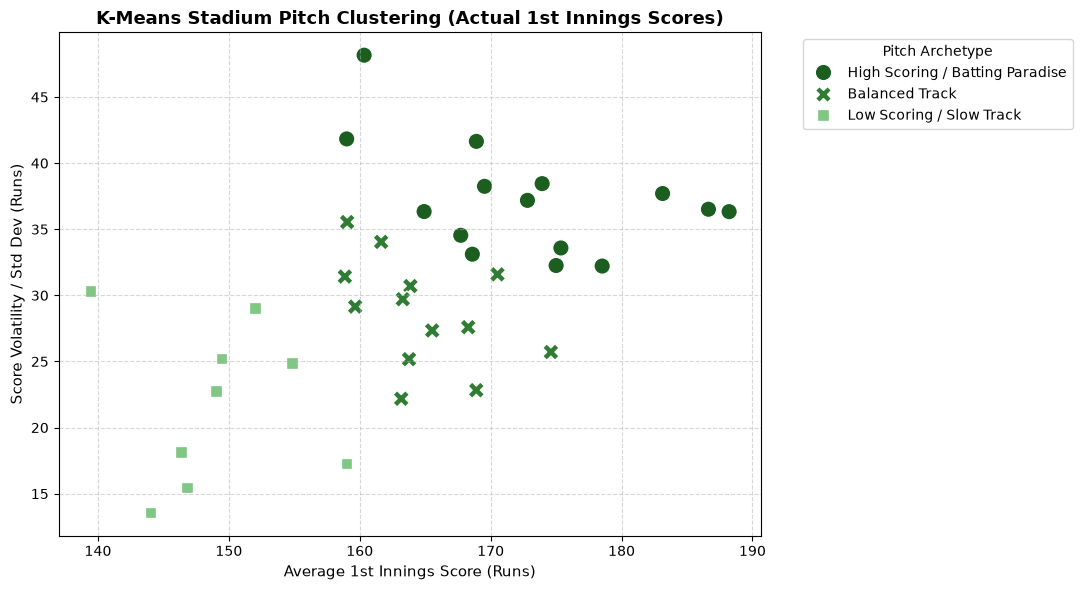

In [18]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load directly from your kagglehub downloaded path
kaggle_path = r"C:\Users\sohag\.cache\kagglehub\datasets\chaitu20\ipl-dataset2008-2025\versions\1\IPL.csv"
df_ball = pd.read_csv(kaggle_path)
df_ball.columns = df_ball.columns.str.strip()

print(f"Total ball-by-ball rows loaded: {len(df_ball):,}")

# 2. Filter for 1st Innings
df_1st = df_ball[df_ball['innings'].astype(str).str.strip().isin(['1', '1.0'])].copy()

# Clean Venue Names
df_1st = df_1st.dropna(subset=['venue']).copy()
df_1st['venue'] = df_1st['venue'].astype(str).str.strip().str.replace(r',.*$', '', regex=True)

# 3. Handle Ball Runs (using runs_total or runs_batter + runs_extras)
if 'runs_total' in df_1st.columns:
    df_1st['ball_runs'] = pd.to_numeric(df_1st['runs_total'], errors='coerce').fillna(0)
else:
    b_runs = pd.to_numeric(df_1st['runs_batter'], errors='coerce').fillna(0) if 'runs_batter' in df_1st.columns else 0
    e_runs = pd.to_numeric(df_1st['runs_extras'], errors='coerce').fillna(0) if 'runs_extras' in df_1st.columns else 0
    df_1st['ball_runs'] = b_runs + e_runs

# 4. CRITICAL STEP: SUM delivery runs per match_id to get actual 1st Innings Match Totals
match_totals = df_1st.groupby(['match_id', 'venue'])['ball_runs'].sum().reset_index()
match_totals.rename(columns={'ball_runs': 'first_innings_score'}, inplace=True)

print(f"Successfully aggregated {len(match_totals)} unique matches.")
print(f"Average 1st Innings Score: {match_totals['first_innings_score'].mean():.1f} runs\n")

# 5. Aggregate Stadium Characteristics (Mean & Volatility)
venue_stats = match_totals.groupby('venue').agg(
    avg_score=('first_innings_score', 'mean'),
    score_std=('first_innings_score', 'std'),
    total_matches=('match_id', 'count')
).reset_index()

venue_stats['score_std'] = venue_stats['score_std'].fillna(0)

# Filter grounds with at least 5 matches for statistical reliability
venue_stats_filtered = venue_stats[venue_stats['total_matches'] >= 5].copy()

# 6. K-Means Pitch Clustering (3 Archetypes)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(venue_stats_filtered[['avg_score', 'score_std']])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
venue_stats_filtered['pitch_type'] = kmeans.fit_predict(X_scaled)

# Order clusters by average score for consistent labelling
cluster_order = venue_stats_filtered.groupby('pitch_type')['avg_score'].mean().sort_values().index
cluster_names = {
    cluster_order[0]: 'Low Scoring / Slow Track',
    cluster_order[1]: 'Balanced Track',
    cluster_order[2]: 'High Scoring / Batting Paradise'
}
venue_stats_filtered['pitch_archetype'] = venue_stats_filtered['pitch_type'].map(cluster_names)

print("=== REAL IPL STADIUM PITCH CLUSTERING RESULTS ===")
print(venue_stats_filtered[['venue', 'avg_score', 'score_std', 'total_matches', 'pitch_archetype']].head(10))

# 7. Scatter Plot
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=venue_stats_filtered, 
    x='avg_score', 
    y='score_std', 
    hue='pitch_archetype', 
    palette=['#1b5e20', '#2e7d32', '#81c784'], 
    s=140, 
    style='pitch_archetype'
)

plt.title('K-Means Stadium Pitch Clustering (Actual 1st Innings Scores)', fontsize=13, fontweight='bold')
plt.xlabel('Average 1st Innings Score (Runs)', fontsize=11)
plt.ylabel('Score Volatility / Std Dev (Runs)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Pitch Archetype', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [19]:
#DOMAIN SPECIFIC FEATURE ENGINEERING (MOMENTUM AND FORTRESS FACTORS)

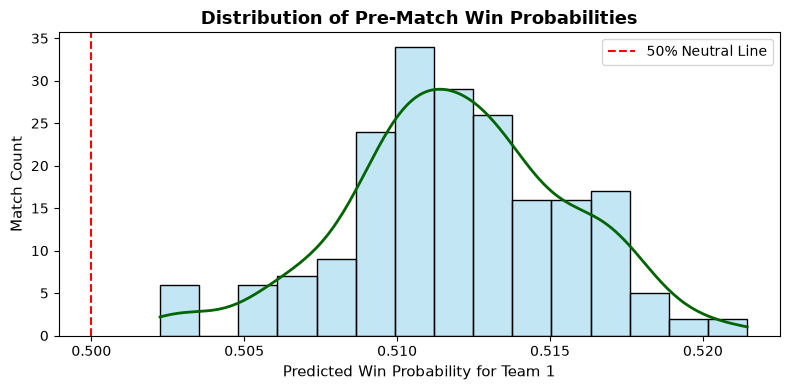

In [20]:
from sklearn.calibration import CalibratedClassifierCV

# Calibrate Random Forest probabilities
calibrated_rf = CalibratedClassifierCV(rf_clf, method='sigmoid', cv=5)
calibrated_rf.fit(X_train_enc, y_train)

# Predict win probability for test matches
win_probs = calibrated_rf.predict_proba(X_test_enc)[:, 1]

# Visualizing Win Probability Distribution 
plt.figure(figsize=(8, 4))
ax = sns.histplot(win_probs, kde=True, color='skyblue', bins=15)

# Find the KDE line object specifically and set its color
for line in ax.lines:
    if line.get_linestyle() != '--':  # Avoid changing your axvline
        line.set_color('darkgreen')
        line.set_linewidth(2)

plt.axvline(0.5, color='red', linestyle='--', label='50% Neutral Line')
plt.title('Distribution of Pre-Match Win Probabilities', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Win Probability for Team 1', fontsize=11)
plt.ylabel('Match Count', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
#EXPLAINABLE AI (SHAP WATERFALLS PLOTS FOR INDIVIDUAL MATCHES)

In [22]:
import shap

# Compute SHAP values for the Random Forest model
explainer = shap.TreeExplainer(rf_clf)
shap_values = explainer.shap_values(X_test_enc)

# Summary Plot: Global feature impact on match outcomes
plt.title("SHAP Feature Impact Summary", fontsize=12, fontweight='bold')
shap.summary_plot(shap_values[1], X_test_enc, feature_names=preprocessor_clf.get_feature_names_out(), show=False)
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'shap'

In [24]:
!pip install shap

   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
    --------------------------------------- 0.8/43.0 MB 287.2 kB/s eta 0:02:27
    --------------------------------------- 0.8/43.0 MB 287.2 kB/s eta 0:02:27
    --------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


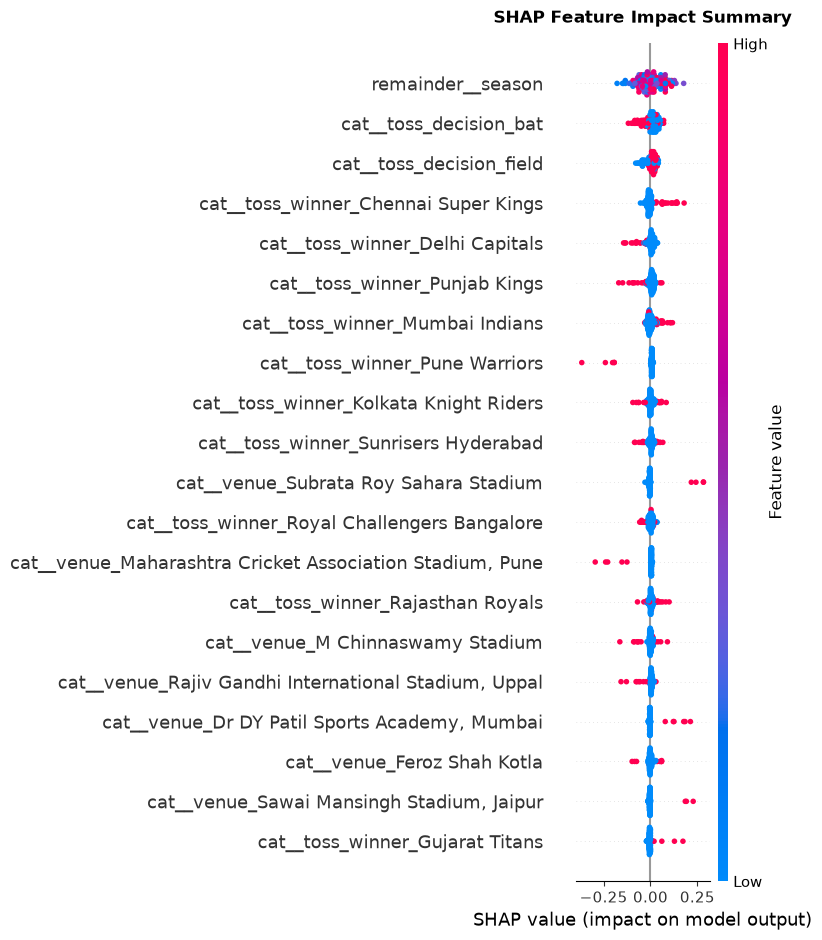

In [26]:
import shap
import matplotlib.pyplot as plt

# 1. Initialize TreeExplainer
explainer = shap.TreeExplainer(rf_clf)

# 2. Compute SHAP values
shap_values = explainer(X_test_enc)

# Handle potential feature name extraction
try:
    feature_names = preprocessor_clf.get_feature_names_out()
except AttributeError:
    feature_names = X_test_enc.columns if hasattr(X_test_enc, 'columns') else None

# 3. Plot SHAP Summary
plt.figure(figsize=(10, 6))

# If shap_values is Explanation object vs raw array
if isinstance(shap_values, shap.Explanation):
    # For binary classification, slice the positive class (class 1)
    if len(shap_values.shape) == 3:  
        shap.summary_plot(shap_values[:, :, 1], feature_names=feature_names, show=False)
    else:
        shap.summary_plot(shap_values, feature_names=feature_names, show=False)
else:
    # Legacy list format fallback
    vals = shap_values[1] if isinstance(shap_values, list) else shap_values
    shap.summary_plot(vals, X_test_enc, feature_names=feature_names, show=False)

plt.title("SHAP Feature Impact Summary", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [ ]:
#INTERACTIVE MATCH PREDICTIVE FUNCTION

In [23]:
def predict_match_outcome(team1, team2, venue, toss_winner, toss_decision, season=2024):
    """
    Custom function to simulate a match setup and print formatted pre-match prediction.
    """
    input_data = pd.DataFrame([{
        'venue': venue,
        'toss_winner': toss_winner,
        'toss_decision': toss_decision,
        'team1': team1,
        'team2': team2,
        'season': season
    }])
    
    # Transform input
    input_enc = preprocessor_clf.transform(input_data)
    
    # Predict Probability
    prob_team1 = calibrated_rf.predict_proba(input_enc)[0][1] * 100
    prob_team2 = 100 - prob_team1
    
    predicted_winner = team1 if prob_team1 >= 50 else team2
    confidence = max(prob_team1, prob_team2)
    
    print("=" * 45)
    print(f"   PRE-MATCH PREDICTION: {team1} vs {team2}")
    print("=" * 45)
    print(f" Venue:         {venue}")
    print(f" Toss Winner:   {toss_winner} ({toss_decision})")
    print("-" * 45)
    print(f" {team1} Win Probability: {prob_team1:.1f}%")
    print(f" {team2} Win Probability: {prob_team2:.1f}%")
    print("-" * 45)
    print(f" PREDICTED WINNER: {predicted_winner} ({confidence:.1f}% Confidence)")
    print("=" * 45)

# Example execution
predict_match_outcome('Mumbai Indians', 'Chennai Super Kings', 'Wankhede Stadium', 'Mumbai Indians', 'field')

   PRE-MATCH PREDICTION: Mumbai Indians vs Chennai Super Kings
 Venue:         Wankhede Stadium
 Toss Winner:   Mumbai Indians (field)
---------------------------------------------
 Mumbai Indians Win Probability: 51.1%
 Chennai Super Kings Win Probability: 48.9%
---------------------------------------------
 PREDICTED WINNER: Mumbai Indians (51.1% Confidence)
